# **Applied Statistics - Assessment Notebook**

### Authored by Stephen Kerr

---

### **Introduction:**

This notebook contains my analysis of the Iris Dataset which is classic multi-class classification dataset. This flower classification dataset from Fisher, 1936 (see documentation [here](https://archive.ics.uci.edu/dataset/53/iris)) was sourced from **Sckit-learn** `load_iris` (see the documentation [here](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html))

The Iris Dataset is one of the earliest used in literature and is used widely for statistics and machine learning. The Image below illustrates the Three Iris Flower Species and their anatomy (Image sourced from [here](https://thedatafrog.com/en/articles/visualizing-datasets/)).


![iris flower image](images\irish_species_image_data_frog.png) 

### Importing the Dataset

The **`load_iris()`** function loads the Iris dataset. 

The dataset is imported as a *'Bunch'* which is a dictionary like-object with the following attributes: 

| **Attribute** | **Description** |
|---|------|
|**'data'** | which is a pandas Dataframe. |
|**'target'** | which is the classification target. |
|**'feature_name'** | which is a list of the dataset columns. |
|**'target_names'** | which is a list of the target classes. |
| **'target'** | attribute is a pandas Series. |
| **'DESCR'** | which is a string that is a full description of the dataset. |
| **'filename'** | which is a string showing the path to the location of the data. |
| **'frame'** | which is a pandas DataFrame with the combination of data and target. |

Note, the Iris Dataset was loaded with the parameter `'as_frame' = 'True` resulting in an *additional attribute* called `'frame'`. 

### Importing Dependenices 

In [2]:
# import numpy as np
import numpy as np

# import pandas as pd
import pandas as pd

# import matplotlib as plt
import matplotlib.pyplot as plt

# import sklearn as skl
from sklearn.datasets import load_iris

# import Ipython.display as display - to display my tables
from IPython.display import display 

# import seaborn as sns
import seaborn as sns

# import scipy.stats as stats
import  scipy.stats as stats

### Load Iris Dataset

In [3]:
# Load the iris data set.
# Note, used the parameter 'as_frame' = True to get the data in a pandas DataFrame.
iris = load_iris(as_frame=True)

In [4]:
print(f'The Iris Data Set is a {type(iris)}\n')

The Iris Data Set is a <class 'sklearn.utils._bunch.Bunch'>



### **Initialisiong the and defining the Iris DataFrame**

In the Iris dataset, the `'frame'` attribute is a Pandas DataFrame that contains the main source of data. To make the dataset more interpretable, we add a new column called 'species'. This column maps the numerical **'target'** values (0, 1, 2) to their corresponding species names ('setosa', 'versicolor', 'virginica').

We achieve this mapping using the `map()` method (see documentation [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.map.html)), which replaces the numerical values in the **'target'** column with their respective species names from the **'target_names'** list creating the new **'species'** column.

Finally, we assign the updated DataFrame to a new variable called `iris_dataframe`, which will be used throughout the analysis.



In [5]:
# To complete the DataFrame we need to add in a 'species' column,
# In order to assign each row to the appropraite species class ['setosa' 'versicolor' 'virginica'],
# We use the map() method the 'target' column of the 'frame' DataFrame and the 'target_names' list,
iris['frame']['species'] = iris['frame']['target'].map({
    0: 'setosa', 
    1: 'versicolor', 
    2: 'virginica'})

# Asigning the 'iris_dataframe' as 'iris['frame'] 
iris_dataframe = iris['frame']

In [6]:
iris_dataframe.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa
5,5.4,3.9,1.7,0.4,0,setosa
6,4.6,3.4,1.4,0.3,0,setosa
7,5.0,3.4,1.5,0.2,0,setosa
8,4.4,2.9,1.4,0.2,0,setosa
9,4.9,3.1,1.5,0.1,0,setosa


**maybe add in some exploreatory / descriptive analysis of the dataset as awhole**

___
## **Problem 1: Exploring Petal Length**

#### **Assesment Brief:**   
Using the Iris dataset, investigate the distribution of `petal_length`.
1. Plot a histogram showing the petal lengths of all 150 flowers.
2. On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.
3. Create separate histograms for each of the three species, and superimpose an appropriate normal distribution on each.
4. Report the mean and standard deviation of petal length for the complete dataset and for each species.
5. Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

### 1 & 2 Histogram of the `petal length` of all 150 flowers & a superimposed normal distribution, using mean and Standard deviation

### Notes:

**What I did and why**
1. **Feature and species:** set `feature = 'petal length (cm)'` and got the three species with `.unique()` so I could split the data by species.
2. **Shared bin edges:** `np.linspace(min, max, 21)` → 20 equal-width bins (~0.295 cm each). All species use the same bins, so the bars line up and can be compared.
3. **Mean and std of all 150 flowers:** μ ≈ 3.76, σ ≈ 1.77. These two values fully define the normal curve. pandas `.std()` gives the *sample* std (ddof=1).
4. **Smooth x-values:** `np.linspace(min, max, 300)` so the curve looks smooth instead of jagged.
5. **One stacked histogram:** passed a list of the three species subsets to a **single** `plt.hist` call with `stacked=True, density=True`.
   - `stacked=True` → the species add on top of each other, so the full stack is all 150 flowers (Task 1), coloured by species.
   - `density=True` → the *combined* stack has total area = 1, the same scale as the normal curve. Without it the bars are counts (up to ~33) and the curve (peak ≈ 0.225) is flattened at the bottom.
   - It must be one call: with `density=True` in a loop, each species is normalised separately (total area 3).
6. **Normal curve:** `stats.norm.pdf(x, mu, sigma)` plotted on the same axes (Task 2).

**Check:** tallest setosa bin = 33 flowers / 150 / 0.295 ≈ 0.75 ✓ matches the plot.

**What the plot shows**
- Two clusters: setosa around 1–2 cm, a gap at ~2.2–2.8 cm with no flowers, then versicolor + virginica overlapping from ~3–7 cm.
- The normal curve peaks at ~3.76 cm, where there is little data, and badly underestimates the setosa peak → a single normal is a poor fit overall.

**Docs:** [plt.hist](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html) · [scipy.stats.norm](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html) · [np.linspace](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html)

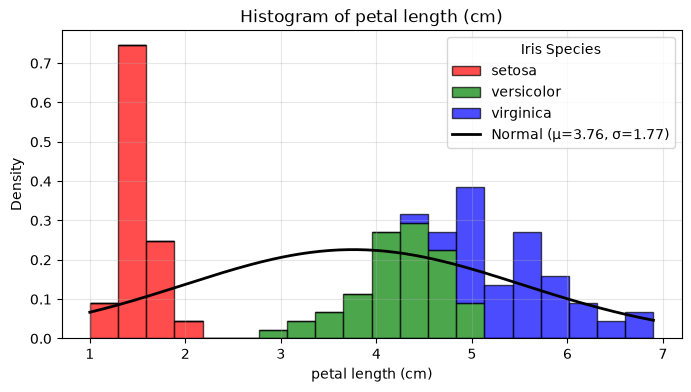

In [7]:
feature = 'petal length (cm)' # define the feature to plot
species = iris_dataframe['species'].unique() # getting the unique species

# define the iris species colours
species_colours = {'setosa': 'red', 'versicolor': 'green', 'virginica': 'blue'}

# shared bin edges so all species use the same bins
bins = np.linspace(iris_dataframe[feature].min(), iris_dataframe[feature].max(), 21)

# Calculate the mean and standard deviation for the feature
mu, sigma = iris_dataframe[feature].mean(), iris_dataframe[feature].std()

# smooth x-values for the curve
x = np.linspace(iris_dataframe[feature].min(), iris_dataframe[feature].max(), 300) 

# Create subsets of the data for each species and their corresponding colours
subsets = [iris_dataframe[iris_dataframe['species'] == s][feature] for s in species]

# Create a list of colours corresponding to each species
colours = [species_colours[s] for s in species]

# Create a histogram for the petal_length feature, with stacked bars for each species
plt.figure(figsize=(8, 4))
# Stacked density histogram (all 150 flowers, total area = 1) with the fitted normal curve on the same scale
plt.hist(subsets, bins=bins, stacked=True, density=True,
         edgecolor='k', alpha=0.7, label=list(species), color=colours)
plt.plot(x, stats.norm.pdf(x, mu, sigma), 'k-', linewidth=2,
         label=f'Normal (μ={mu:.2f}, σ={sigma:.2f})')
plt.title(f'Histogram of {feature}') # title of the graph
plt.xlabel(feature) # x-axis label
plt.ylabel('Density') # y-axis label
plt.legend(title='Iris Species') # add the legend
plt.grid(True, alpha=0.3)
plt.show()

#### 3. Seperate histogram for each Species with an appropriate normal distribution

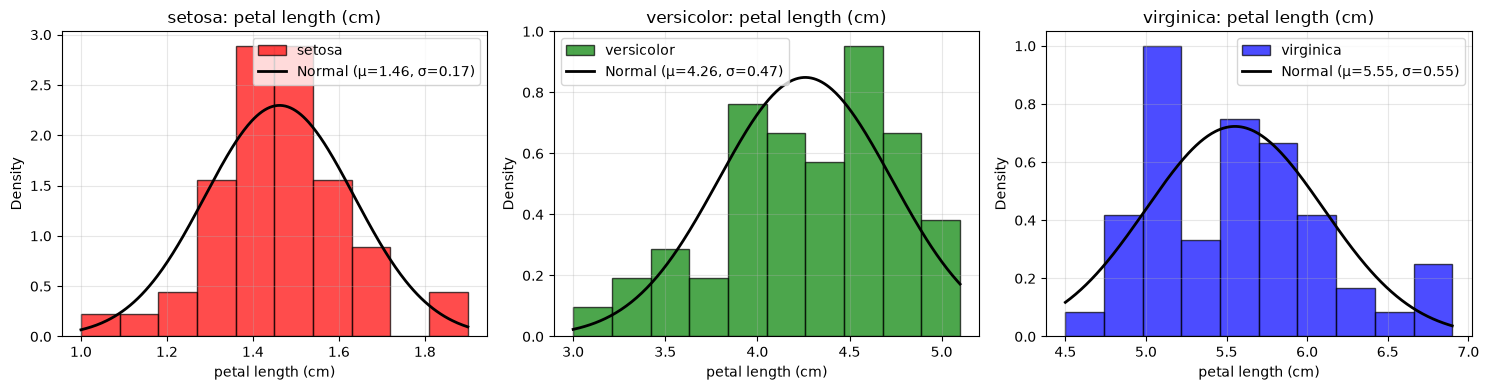

In [8]:
# Task 3: separate histogram for each species with its own fitted normal curve
fig, axes = plt.subplots(1, 3, figsize=(15, 4))   # 1 row, 3 plots

for ax, s, subset in zip(axes, species, subsets):   # pair each axis with a species and its data
    mu_s, sigma_s = subset.mean(), subset.std()      # this species' mean and sample std
    x_s = np.linspace(subset.min(), subset.max(), 300)

    ax.hist(subset, bins=10, density=True, edgecolor='k', alpha=0.7,
            color=species_colours[s], label=s)
    ax.plot(x_s, stats.norm.pdf(x_s, mu_s, sigma_s), 'k-', linewidth=2,
            label=f'Normal (μ={mu_s:.2f}, σ={sigma_s:.2f})')

    ax.set_title(f'{s}: {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Density')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show() 

___
## **Problem 2: Correlation Between Petal Length and Petal Width**

#### **Assesment Brief:**   

Investigate the relationship between `petal_length` and `petal_width` in the Iris dataset.
1. Calculate the Pearson correlation coefficient between petal length and petal width using all 150 flowers.
2. Create an appropriate scatter plot showing the relationship between the two variables, and include a suitable line to help illustrate the relationship.
3. Calculate the Pearson correlation coefficient separately for each of the three species.
4. Create an appropriate plot showing the relationship between petal length and petal width for each species.
5. Report and compare the correlation coefficients.
6. Explain what the correlation coefficients tell you about the relationship between petal length and petal width, both for the dataset as a whole and within each species.

___
## **Problem 3: Comparing Species Using t-Tests**

#### **Assesment Brief:**  

Investigate whether the three iris species differ in their `petal_length` and `petal_width`.

For each pair of species:
- `setosa` vs `versicolor`
- `setosa` vs `virginica`
- `versicolor` vs `virginica`
perform an independent-samples t-test for:

- petal length,
- petal width.

For each test:
1. State the null and alternative hypotheses.
2. Calculate the t-statistic and p-value using scipy.stats.
3. Use a significance level of α = 0.05 to decide whether to reject the null hypothesis.
4. Summarise your results in an appropriate table.
5. Explain what the results tell you about differences between the three species.

___
## **Problem 4: Comparing the Species Using ANOVA**

#### **Assesment Brief:**  

The t-tests in Problem 3 require several separate comparisons between species. Instead, investigate differences in petal length and petal width using one-way analysis of variance (ANOVA).

For each variable:

1. State the null and alternative hypotheses for a one-way ANOVA.
2. Perform a one-way ANOVA comparing the three species using `scipy.stats`.
3. Report the F-statistic and p-value.
4. Use a significance level of α = 0.05 to determine whether there is evidence that the species have different population means.
5. Explain what the ANOVA result tells you and what it does not tell you about the individual species.

The t-tests in Problem 3 involved three pairwise comparisons. Explain why performing several separate hypothesis tests can increase the overall probability of making a type I error, and explain how ANOVA addresses this problem by testing the three group means simultaneously.

Finally, compare the conclusions from your t-tests with those from the ANOVA and explain why ANOVA is generally preferable when comparing more than two groups.


___
# End